In [49]:
import os 
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from morph_utils.templates import load_layer_template 
from morph_utils.query import get_id_by_name

from scipy.stats import kruskal, mannwhitneyu, chi2_contingency, fisher_exact
import scikit_posthocs as spoc
from itertools import combinations
from statsmodels.stats.multitest import fdrcorrection, multipletests
from statannotations.Annotator import Annotator
from matplotlib.patches import Rectangle
import itertools

import sys 
sys.path.append('/root/capsule/code/figures') 
from morphology_utils import AVERAGE_DISTANCE_BETWEEN_NODES
from core_utils import get_seaad_colors

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator

In [50]:
species_type = 'primate' #'primate', 'species'

dataset_type = '_inclusive' #'_inclusive', ''  --- '' is restricted to L5 IT in Layer 5, '_inclusive' includes L5 IT not in Layer 5

depth_type = 'layer' # depth_in_layer_norm used to define superficial/deep L2/3 IT groups
# depth_type = 'pia' # depth_from_pia_norm used to define superficial/deep L2/3 IT groups


Calculate amount of apical in L1 per cell

In [51]:
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

h_data_file =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'AlignedHistogram.csv'
q_data_file =      DATA_ROOT / 'macaque' / 'morphology' / 'dendrite' / '20260722' / 'AlignedHistogram.csv'
m_data_file =      DATA_ROOT / 'mouse' / 'morphology' / 'dendrite' / '20260826' / f'AlignedHistogram{dataset_type}.csv'

macaque_average_layers_file =   DATA_ROOT / 'macaque' / 'average_cortical_layers' / '20250314' / 'macaque_average_layers.json'

#colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'


#colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))

h_data = pd.read_csv(h_data_file, index_col='specimen_id')
q_data = pd.read_csv(q_data_file, index_col='specimen_id')
m_data = pd.read_csv(m_data_file, index_col='specimen_id')
bin_size = 5 #um width of histogram bins

#keep apical columns
compartment = 4
h_data = h_data[[c for c in h_data.columns if c.startswith(f'{compartment}_')]]
q_data = q_data[[c for c in q_data.columns if c.startswith(f'{compartment}_')]]
m_data = m_data[[c for c in m_data.columns if c.startswith(f'{compartment}_')]]

#scale from node count to um 
h_data = h_data * AVERAGE_DISTANCE_BETWEEN_NODES
q_data = q_data * AVERAGE_DISTANCE_BETWEEN_NODES
m_data = m_data * AVERAGE_DISTANCE_BETWEEN_NODES

#Get L1 boundary
pia_buffer = 0 #5
human_layers, _, _ = load_layer_template('human')
h_pia = human_layers['2'] + pia_buffer 
h_pia_bin = round(h_pia/bin_size)

with open(macaque_average_layers_file, "r") as file:
    macaque_layers = json.load(file)
q_pia = macaque_layers['2'] + pia_buffer 
q_pia_bin = round(q_pia/bin_size)

mouse_layers, _, _ = load_layer_template('mouse')
m_pia = mouse_layers['2/3'] + pia_buffer 
m_pia_bin = round(m_pia/bin_size)

#keep data in L1
l1_cols = [f'{compartment}_{i}' for i in range(0, h_pia_bin+1)]
h_data = h_data[l1_cols]
q_data = q_data[l1_cols]
m_data = m_data[l1_cols]

#sum apical in L1
h_data['apical_l1_sum_um'] = h_data.sum(axis=1)
h_data = h_data.sort_values(by='apical_l1_sum_um', ascending=False)

q_data['apical_l1_sum_um'] = q_data.sum(axis=1)
q_data = q_data.sort_values(by='apical_l1_sum_um', ascending=False)

m_data['apical_l1_sum_um'] = m_data.sum(axis=1)
m_data = m_data.sort_values(by='apical_l1_sum_um', ascending=False)

#remove cells with no apical in layer 1
h_data = h_data[h_data.apical_l1_sum_um > 0]
q_data = q_data[q_data.apical_l1_sum_um > 0]
m_data = m_data[m_data.apical_l1_sum_um > 0]

#combine species data 
h_data['species'] = 'human'
q_data['species'] = 'macaque'
m_data['species'] = 'mouse'

all_species_apical_data = pd.concat([h_data[['apical_l1_sum_um', 'species']], q_data[['apical_l1_sum_um', 'species']], m_data[['apical_l1_sum_um', 'species']]])

#save 
h_data.to_csv(os.path.join(OUT_DIR, 'human_apical_l1.csv'))
q_data.to_csv(os.path.join(OUT_DIR, 'macaque_apical_l1.csv'))
m_data.to_csv(os.path.join(OUT_DIR, 'mouse_apical_l1.csv'))
all_species_apical_data.to_csv(os.path.join(OUT_DIR, 'all_species_apical_l1.csv'))

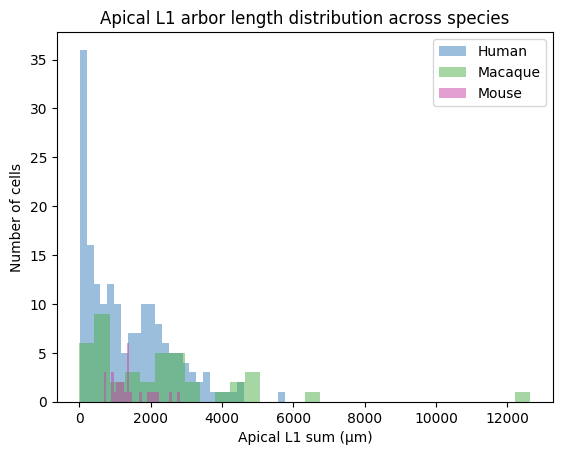

In [52]:
plt.hist(h_data.apical_l1_sum_um.tolist(), bins=30, color=species_colors['human'], alpha=0.5, label='Human')
plt.hist(q_data.apical_l1_sum_um.tolist(), bins=30, color=species_colors['macaque'], alpha=0.5, label='Macaque')
plt.hist(m_data.apical_l1_sum_um.tolist(), bins=30, color=species_colors['mouse'], alpha=0.5, label='Mouse')

plt.xlabel('Apical L1 sum (µm)')
plt.ylabel('Number of cells')
plt.title('Apical L1 arbor length distribution across species')
plt.legend()
plt.show()


<Axes: xlabel='apical_l1_sum_um', ylabel='species'>

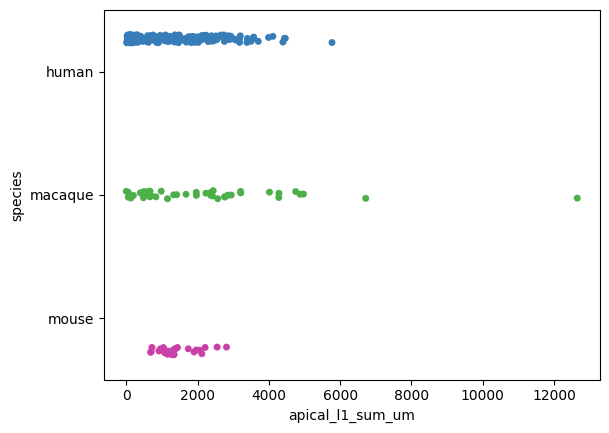

In [53]:
sns.stripplot(x='apical_l1_sum_um', y='species', hue='species', data=all_species_apical_data, dodge=True, jitter=True, palette=species_colors)


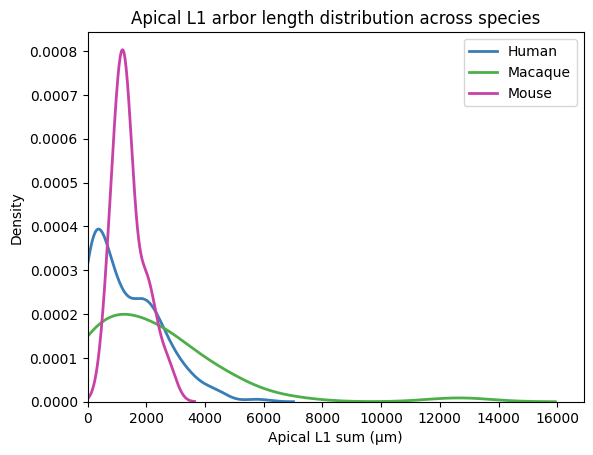

In [54]:
sns.kdeplot(h_data.apical_l1_sum_um, color=species_colors['human'], fill=False, label='Human', linewidth=2)
sns.kdeplot(q_data.apical_l1_sum_um, color=species_colors['macaque'], fill=False, label='Macaque', linewidth=2)
sns.kdeplot(m_data.apical_l1_sum_um, color=species_colors['mouse'], fill=False, label='Mouse', linewidth=2)

plt.xlabel('Apical L1 sum (µm)')
plt.ylabel('Density')
plt.title('Apical L1 arbor length distribution across species')
plt.legend()
plt.xlim(left=0)
plt.show()


Get average L1 apical per subclass

In [55]:
#human
h_subclass_col = 'subclass_label_Hierarchical' #'subclass_Corr_label_RSC_122-389'
h_cluster_col = 'cluster_label_Hierarchical' #'cluster_Corr_label_RSC_122-389'

#macaque
p_subclass_col =  'subclass_Corr_label_RSC_204_389'
p_cluster_col =   'cluster_Corr_label_RSC_204_389'

#mouse
m_subclass_col =  'subclass'
m_cluster_col =  't_type'

#rename to
subclass_col =  'subclass'
cluster_col =   'cluster'


if species_type == 'primate':
    subclass_order = ['L2/3 IT_superficial', 'L2/3 IT_deep', 'L5/6 NP', 'L5 IT', 'L5 ET']
    species_order = ['human', 'macaque']
else:
    subclass_order = ['L5 IT', 'L5 ET']
    species_order = ['human', 'macaque', 'mouse']



In [56]:
# Save root 
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

# HUMAN TemL
human_metadata_file =     DATA_ROOT / 'human' / 'metadata'   / '20260807' / 'human_metadata.csv'
human_feature_file =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'RawFeatureWide.csv'

# MACAQUE TemL
macaque_metadata_file =         DATA_ROOT / 'macaque' / 'metadata'   / '20260722' / 'macaque_metadata.csv'
macaque_feature_file =          DATA_ROOT / 'macaque' / 'morphology' / 'dendrite' / '20260722' / 'RawFeatureWide.csv'

# MOUSE TEa
mouse_metadata_file =     DATA_ROOT / 'mouse' / 'metadata'   / '20260826' / 'mouse_metadata.csv'
mouse_feature_file =      DATA_ROOT / 'mouse' / 'morphology' / 'dendrite' / '20260826' / f'RawFeatureWide{dataset_type}.csv' # 'RawFeatureWide_inclusive.csv'

# depth alignment
l23_grouping_file =         OUT_DIR / f'l23_comparison_{depth_type}.csv'

#colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'

#subclass order
subclass_order_file =         DATA_ROOT / 'formatting_dicts' / 'subclass_order.txt'


In [57]:
# HUMAN TemL
human_metadata = pd.read_csv(human_metadata_file)
human_metadata[h_subclass_col] = human_metadata[h_subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
human_metadata[h_cluster_col] = human_metadata[h_cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
human_metadata = human_metadata[human_metadata.lobe == 'TemL']
human_raw_feature_wide = pd.read_csv(human_feature_file)
human_metadata = human_metadata.rename(columns={h_subclass_col: subclass_col, h_cluster_col: cluster_col, 'cell_id': 'specimen_id'})
human_metadata = human_metadata.dropna(subset=[subclass_col, cluster_col])
human_metadata['species'] = 'human'

#MACAQUE TemL
macaque_metadata = pd.read_csv(macaque_metadata_file)
macaque_metadata = macaque_metadata[macaque_metadata.Morphology == True]
macaque_raw_feature_wide = pd.read_csv(macaque_feature_file)
macaque_metadata = macaque_metadata[macaque_metadata.specimen_id.isin(macaque_raw_feature_wide.specimen_id.tolist())]
macaque_metadata = macaque_metadata.rename(columns={p_subclass_col: subclass_col, p_cluster_col: cluster_col})
macaque_metadata['species'] = 'macaque'

#MOUSE TEa
mouse_metadata = pd.read_csv(mouse_metadata_file)
mouse_raw_feature_wide = pd.read_csv(mouse_feature_file).rename(columns={'Unnamed: 0': 'specimen_id'})
mouse_metadata = mouse_metadata.rename(columns={m_subclass_col: subclass_col, m_cluster_col: cluster_col, 'Cell Specimen Id': 'specimen_id'})
mouse_metadata[subclass_col] = (
    mouse_metadata[subclass_col]
    .str.replace('-', '/', regex=False)
    .str.replace('_', ' ', regex=False)
)
mouse_metadata['species'] = 'mouse'
mouse_metadata[cluster_col] = 'Unknown'

#depth matching groups for L2/3 IT subclass
l23_grouping_data = pd.read_csv(l23_grouping_file)

#colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))
species_colors['mouse TEa'] = '#c9416a'
species_colors['mouse VIS'] = species_colors['mouse']

#get plotting color dict
color_dict = get_seaad_colors()
color_dict['L2/3 IT_superficial'] = color_dict['L2/3 IT']
color_dict['L2/3 IT_deep'] = color_dict['L2/3 IT']



cluster_var_name = subclass_col

#combine data 
human_data = human_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(human_raw_feature_wide, how='inner', on='specimen_id')
macaque_data = macaque_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(macaque_raw_feature_wide, how='inner', on='specimen_id')
mouse_data = mouse_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(mouse_raw_feature_wide, how='inner', on='specimen_id')

#select region/species data to analyze
if species_type == 'species':
    data = pd.concat([human_data, macaque_data, mouse_data]).set_index('specimen_id')
elif species_type == 'primate':
    data = pd.concat([human_data, macaque_data]).set_index('specimen_id')
else: raise ValueError(f'Unknown species_type: {species_type}')

data['dendrite_total_length'] = data['apical_dendrite_total_length'] + data['basal_dendrite_total_length']

#drop axon columns (computed for TEa but shouldn't be included)
cols_to_drop = data.columns[data.isna().sum() >= 50]
data = data.drop(columns=cols_to_drop)

In [58]:
# L2/3 IT subclass depth matching 
l23_grouping_col = 'depth_group_two' 

#append the grouping to L2/3 IT subclass name (i.e. '_superficial', '_deep')
id_to_group = l23_grouping_data.set_index('specimen_id')[l23_grouping_col]
mask = data.index.isin(id_to_group.index)
data.loc[mask, 'subclass'] = (
    data.loc[mask, 'subclass'] + '_' + data.index[mask].map(id_to_group)
)

data = data[data.subclass != 'L2/3 IT'] # remove the L2/3 IT cells that did not have a depth match, these are < 0.2 normalized depth, and so are likely Layer 2 cells (macaque doesn't have any)

In [59]:
data.subclass.value_counts()

L4 IT                  57
L5 IT                  45
L2/3 IT_deep           42
L2/3 IT_superficial    38
L5 ET                  23
L5/6 NP                14
L6 IT Car3             13
L6 IT                  10
L6b                     8
L6 CT                   5
Name: subclass, dtype: int64

In [60]:
data = data[['subclass', 'cluster', 'species']].merge(all_species_apical_data[['apical_l1_sum_um']], how='inner', left_index=True, right_index=True)
data

,subclass,cluster,species,apical_l1_sum_um
specimen_id,,,,
6.540225e+08,L5 ET,L5 ET_1,human,2129.52
6.541808e+08,L2/3 IT_superficial,L2/3 IT_6,human,2299.38
6.858063e+08,L2/3 IT_superficial,L2/3 IT_1,human,3066.60
6.858159e+08,L2/3 IT_deep,L2/3 IT_12,human,137.94
6.893091e+08,L2/3 IT_superficial,L2/3 IT_2,human,2390.58
...,...,...,...,...
1.142313e+09,L5 ET,L5 ET_1,macaque,2416.80
1.230044e+09,L5 ET,L5 ET_1,macaque,1678.08
1.272206e+09,L5 IT,L5 IT_2,macaque,3.42


Stats

In [61]:
x_var = 'subclass'
x_var_order = subclass_order
feature = 'apical_l1_sum_um'

mn_pvals = {}
mn_test_type = {}
mn_posthoc_pvals = {}

# PASS 1: Run all main tests (Kruskal-Wallis or Mann-Whitney)
for var in x_var_order:
    group_human = data.loc[(data[x_var] == var) & (data.species == 'human')][feature].dropna().tolist()
    group_macaque = data.loc[(data[x_var] == var) & (data.species == 'macaque')][feature].dropna().tolist()
    group_mouse = data.loc[(data[x_var] == var) & (data.species == 'mouse')][feature].dropna().tolist()

    groups = {'human': group_human, 'macaque': group_macaque, 'mouse': group_mouse}

    non_empty = {k: v for k, v in groups.items() if len(v) > 0}

    if len(non_empty) < 2:
        print(f'Skipping {feature} in {var}: fewer than two species have values.')
        mn_pvals[var] = np.nan
        mn_test_type[var] = 'none'
        continue

    try:
        if len(non_empty) >= 3:
            # Kruskal–Wallis 3-way test
            stat, pval = kruskal(*non_empty.values(), nan_policy='omit')
            mn_test_type[var] = 'kruskal'
            mn_pvals[var] = pval

        else:
            # Mann–Whitney for 2 species
            vals = list(non_empty.values())
            stat, pval = mannwhitneyu(vals[0], vals[1], nan_policy='omit')
            mn_test_type[var] = 'mannwhitneyu'
            mn_pvals[var] = pval

    except Exception as e:
        print(f"Couldn't compute stats for {feature} in {var}: {e}")
        mn_pvals[var] = np.nan
        mn_test_type[var] = 'error'

# FDR correction for KW/MW main tests
pvals = np.array([p for p in mn_pvals.values() if not np.isnan(p)])
if len(pvals):
    rejected, pvals_fdr = fdrcorrection(pvals, alpha=0.05)
    valid_keys = [k for k, v in mn_pvals.items() if not np.isnan(v)]
    mn_pvals_fdr = dict(zip(valid_keys, pvals_fdr))
    mn_pvals_rejected = dict(zip(valid_keys, rejected))
else:
    mn_pvals_fdr = {k: np.nan for k in mn_pvals.keys()}
    mn_pvals_rejected = {k: False for k in mn_pvals.keys()}

# PASS 2: Run posthoc tests only for FDR-significant Kruskal-Wallis tests
for var in x_var_order:
    group_human = data.loc[(data[x_var] == var) & (data.species == 'human')][feature].dropna().tolist()
    group_macaque = data.loc[(data[x_var] == var) & (data.species == 'macaque')][feature].dropna().tolist()
    group_mouse = data.loc[(data[x_var] == var) & (data.species == 'mouse')][feature].dropna().tolist()

    groups = {'human': group_human, 'macaque': group_macaque, 'mouse': group_mouse}
    non_empty = {k: v for k, v in groups.items() if len(v) > 0}
    
    if len(non_empty) < 2:
        mn_posthoc_pvals[var] = {}
        continue

    try:
        if len(non_empty) >= 3:
            # If Kruskal significant after FDR correction, run Dunn's posthoc
            if mn_pvals_rejected.get(var, False):
                df_subset = data.loc[data[x_var] == var, ['species', feature]]
                posthoc = spoc.posthoc_dunn(df_subset, val_col=feature, group_col='species', p_adjust='fdr_bh')
                species_list = list(non_empty.keys())
                mn_posthoc_pvals[var] = {
                    f"{s1}_vs_{s2}": posthoc.loc[s1, s2]
                    for s1, s2 in combinations(species_list, 2)
                }
            else:
                mn_posthoc_pvals[var] = {}

        else:
            # Mann–Whitney for 2 species - store the main p-value as the posthoc result
            sp_keys = list(non_empty.keys())
            mn_posthoc_pvals[var] = {f"{sp_keys[0]}_vs_{sp_keys[1]}": mn_pvals[var]}

    except Exception as e:
        print(f"Couldn't compute posthoc for {feature} in {var}: {e}")
        mn_posthoc_pvals[var] = {}

# Combine all results into one tidy DataFrame
rows = []
for subclass in mn_pvals.keys():
    row = {
        'subclass': subclass,
        'test_type': mn_test_type[subclass],
        'p_value': mn_pvals[subclass],
        'p_value_fdr': mn_pvals_fdr.get(subclass, np.nan),
        'significant': mn_pvals_rejected.get(subclass, False)
    }
    # flatten Dunn's posthoc p-values if present
    if subclass in mn_posthoc_pvals.keys():
        for comp, pval in mn_posthoc_pvals[subclass].items():
            row[comp] = pval
        rows.append(row)
results = pd.DataFrame(rows)

In [62]:
results

,subclass,test_type,p_value,p_value_fdr,significant,human_vs_macaque
0,L2/3 IT_superficial,mannwhitneyu,0.023868,0.119341,False,0.023868
1,L2/3 IT_deep,mannwhitneyu,0.054462,0.134865,False,0.054462
2,L5/6 NP,mannwhitneyu,0.400000,0.400000,False,0.400000
3,L5 IT,mannwhitneyu,0.107892,0.134865,False,0.107892
4,L5 ET,mannwhitneyu,0.083214,0.134865,False,0.083214


In [63]:
results.to_csv(os.path.join(OUT_DIR, f'{species_type}_average_l1_apical_length_stats.csv'), index=False)

# Apical reach stats

Do species apicals reach L1 the same amount per subclass?

In [64]:
# Load FULL dataset for reach analysis (don't filter by apical_l1_sum_um > 0)

# Reload the histogram data without filtering
full_h_data = pd.read_csv(h_data_file, index_col='specimen_id')
full_q_data = pd.read_csv(q_data_file, index_col='specimen_id')
full_m_data = pd.read_csv(m_data_file, index_col='specimen_id')

# Keep apical columns
full_h_data = full_h_data[[c for c in full_h_data.columns if c.startswith(f'{compartment}_')]]
full_q_data = full_q_data[[c for c in full_q_data.columns if c.startswith(f'{compartment}_')]]
full_m_data = full_m_data[[c for c in full_m_data.columns if c.startswith(f'{compartment}_')]]

# Scale from node count to um
full_h_data = full_h_data * AVERAGE_DISTANCE_BETWEEN_NODES
full_q_data = full_q_data * AVERAGE_DISTANCE_BETWEEN_NODES
full_m_data = full_m_data * AVERAGE_DISTANCE_BETWEEN_NODES

# Keep data in L1 (same bins as before)
full_h_data = full_h_data[l1_cols]
full_q_data = full_q_data[l1_cols]
full_m_data = full_m_data[l1_cols]

# Sum apical in L1 (but DON'T filter by > 0)
full_h_data['apical_l1_sum_um'] = full_h_data.sum(axis=1)
full_q_data['apical_l1_sum_um'] = full_q_data.sum(axis=1)
full_m_data['apical_l1_sum_um'] = full_m_data.sum(axis=1)

# Add species column
full_h_data['species'] = 'human'
full_q_data['species'] = 'macaque'
full_m_data['species'] = 'mouse'

# Reload metadata to get ALL cells (not just those with apical in L1)
full_human_metadata = human_metadata[['specimen_id', subclass_col, cluster_col]].copy()
full_macaque_metadata = macaque_metadata[['specimen_id', subclass_col, cluster_col]].copy()
full_mouse_metadata = mouse_metadata[['specimen_id', subclass_col, cluster_col]].copy()

# Merge apical data with metadata
full_h_reach = full_h_data[['apical_l1_sum_um', 'species']].merge(
    full_human_metadata.set_index('specimen_id'), 
    left_index=True, right_index=True, how='inner'
)
full_q_reach = full_q_data[['apical_l1_sum_um', 'species']].merge(
    full_macaque_metadata.set_index('specimen_id'), 
    left_index=True, right_index=True, how='inner'
)
full_m_reach = full_m_data[['apical_l1_sum_um', 'species']].merge(
    full_mouse_metadata.set_index('specimen_id'), 
    left_index=True, right_index=True, how='inner'
)

# Combine all species
full_data_for_reach = pd.concat([full_h_reach, full_q_reach, full_m_reach])

# Apply L2/3 IT depth matching to full dataset
l23_grouping_col = 'depth_group_two'
id_to_group = l23_grouping_data.set_index('specimen_id')[l23_grouping_col]
mask = full_data_for_reach.index.isin(id_to_group.index)
full_data_for_reach.loc[mask, subclass_col] = (
    full_data_for_reach.loc[mask, subclass_col] + '_' + full_data_for_reach.index[mask].map(id_to_group)
)
# Remove L2/3 IT cells without depth match
full_data_for_reach = full_data_for_reach[full_data_for_reach[subclass_col] != 'L2/3 IT']

print(f"Full dataset size: {len(full_data_for_reach)}")
print(f"Cells with apical in L1: {(full_data_for_reach['apical_l1_sum_um'] > 0).sum()}")
print(f"Cells WITHOUT apical in L1: {(full_data_for_reach['apical_l1_sum_um'] == 0).sum()}")
print(f"\nBreakdown by species:")
print(full_data_for_reach.groupby('species')['apical_l1_sum_um'].apply(lambda x: (x > 0).sum()))

Full dataset size: 281
Cells with apical in L1: 157
Cells WITHOUT apical in L1: 124

Breakdown by species:
species
human      89
macaque    42
mouse      26
Name: apical_l1_sum_um, dtype: int64


In [65]:
# Mark which cells have apical reaching L1 (use FULL unfiltered dataset)
full_data_for_reach['reaches_l1'] = full_data_for_reach['apical_l1_sum_um'] > 0

print(f"\nSubclass breakdown:")
print(full_data_for_reach.groupby([subclass_col, 'species'])['reaches_l1'].value_counts().unstack(fill_value=0))

full_data_for_reach


Subclass breakdown:
reaches_l1                   False  True 
subclass            species              
L2/3 IT_deep        human        6     25
                    macaque      0     11
                    mouse        0      1
L2/3 IT_superficial human        0     31
                    macaque      0      7
                    mouse        0      2
L4 IT               human       44     13
                    mouse        0      3
L5 ET               human        0      9
                    macaque      0     14
                    mouse        0      3
L5 IT               human       27      8
                    macaque      4      6
                    mouse        0     16
L5/6 NP             human        9      2
                    macaque      0      3
L6 CT               human        5      0
                    mouse        0      1
L6 IT               human        6      0
                    macaque      3      1
L6 IT Car3          human       12      1
L6b          

,apical_l1_sum_um,species,subclass,cluster,reaches_l1
specimen_id,,,,,
5.397370e+08,3703.86,human,L2/3 IT_superficial,L2/3 IT_8,True
5.415493e+08,1987.02,human,L2/3 IT_superficial,L2/3 IT_6,True
5.717327e+08,1668.96,human,L2/3 IT_deep,L2/3 IT_12,True
5.881574e+08,1374.84,human,L2/3 IT_deep,L2/3 IT_13,True
5.924800e+08,0.00,human,L6b,L6b_3,False
...,...,...,...,...,...
8.994857e+08,1324.68,mouse,L5 IT,Unknown,True
8.508009e+08,722.76,mouse,L4 IT,Unknown,True
8.518330e+08,917.70,mouse,L4 IT,Unknown,True


In [66]:
# Statistical tests for apical reach by subclass
all_results = []
summary_tables = []

reach_data = full_data_for_reach  # Use the full unfiltered dataset

for subclass in reach_data[subclass_col].unique():
    subclass_data = reach_data[reach_data[subclass_col] == subclass]

    # contingency table (species × reaches_l1)
    table = pd.crosstab(subclass_data['species'], subclass_data['reaches_l1'])
    chi2, p, dof, expected = chi2_contingency(table)

    # summarize counts (reaches vs doesn't reach)
    summary = (
        subclass_data
        .groupby([subclass_col, 'species', 'reaches_l1'])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )
    
    # Ensure both columns exist
    if True not in summary.columns:
        summary[True] = 0
    if False not in summary.columns:
        summary[False] = 0
    
    summary = summary.rename(columns={True: 'count_reaches_L1', False: 'count_does_not_reach_L1', subclass_col: 'subclass'})
    summary_tables.append(summary)

    # pairwise species post hoc tests
    species_list = subclass_data['species'].unique()
    pairs = list(itertools.combinations(species_list, 2))
    subclass_results = []
    for s1, s2 in pairs:
        subset = subclass_data[subclass_data['species'].isin([s1, s2])]
        pair_table = pd.crosstab(subset['species'], subset['reaches_l1'])

        if pair_table.shape == (2, 2):
            _, p_pair = fisher_exact(pair_table)
        else:
            p_pair = float('nan')

        subclass_results.append((s1, s2, p_pair))

    # FDR correction within subclass (pairwise tests)
    pvals = [r[2] for r in subclass_results if not pd.isna(r[2])]
    if len(pvals) > 0:
        reject, pvals_corrected, _, _ = multipletests(pvals, method='fdr_bh')
    else:
        reject, pvals_corrected = [], []

    out = []
    j = 0
    for (s1, s2, p_pair) in subclass_results:
        if pd.isna(p_pair):
            out.append((subclass, s1, s2, chi2, p, dof, p_pair, None, None))
        else:
            out.append((subclass, s1, s2, chi2, p, dof, p_pair, pvals_corrected[j], reject[j]))
            j += 1

    posthoc_df = pd.DataFrame(out, columns=[
        'Subclass', 'Species1', 'Species2',
        'Chi2', 'Chi2_p', 'Chi2_dof',
        'Pairwise_p', 'FDR_p', 'Pairwise_Significant'
    ])
    all_results.append(posthoc_df)

# combine all subclasses
all_results_df = pd.concat(all_results, ignore_index=True)

# FDR correction across subclasses for overall chi²
chi_pvals = all_results_df[['Subclass', 'Chi2_p']].drop_duplicates()
reject, pvals_corrected, _, _ = multipletests(chi_pvals['Chi2_p'], method='fdr_bh')
chi_pvals['Chi2_FDR_p'] = pvals_corrected
chi_pvals['Chi2_Significant'] = reject

# merge back
all_results_df = all_results_df.merge(
    chi_pvals, on=['Subclass', 'Chi2_p'], how='left'
)

all_results_df = all_results_df[['Subclass', 'Species1', 'Species2', 'Chi2', 'Chi2_dof', 'Chi2_p', 'Chi2_FDR_p', 'Chi2_Significant', 'Pairwise_p', 'FDR_p', 'Pairwise_Significant']]

# combine all subclass × species summaries
summary_df = pd.concat(summary_tables, ignore_index=True)
summary_df = summary_df.fillna(0)
summary_df['percent_reaches_L1'] = 100*(summary_df['count_reaches_L1']/
                                        (summary_df['count_reaches_L1']+summary_df['count_does_not_reach_L1']))

In [67]:
# Save results
all_results_df.to_csv(os.path.join(OUT_DIR, f'{species_type}_subclass_apical_reaches_l1_stats.csv'), index=False)
summary_df.to_csv(os.path.join(OUT_DIR, f'{species_type}_subclass_apical_reaches_l1_counts.csv'), index=False)

summary_df

reaches_l1,subclass,species,count_reaches_L1,count_does_not_reach_L1,percent_reaches_L1
0,L2/3 IT_superficial,human,31,0,100.000000
1,L2/3 IT_superficial,macaque,7,0,100.000000
2,L2/3 IT_superficial,mouse,2,0,100.000000
3,L2/3 IT_deep,human,25,6,80.645161
4,L2/3 IT_deep,macaque,11,0,100.000000
5,L2/3 IT_deep,mouse,1,0,100.000000
6,L6b,human,0,6,0.000000
7,L6b,macaque,0,2,0.000000
8,L4 IT,human,13,44,22.807018
9,L4 IT,mouse,3,0,100.000000


Heatmap

In [68]:
# Format data for heatmap - use subclass_order based on species_type
if species_type == 'primate':
    keep_subclasses = ['L2/3 IT_superficial', 'L2/3 IT_deep', 'L5 IT', 'L5/6 NP', 'L5 ET']
else:  # species
    keep_subclasses = ['L5 IT', 'L5 ET']

# Filter to subclasses that exist in the data
keep_subclasses = [sc for sc in keep_subclasses if sc in summary_df.subclass.unique()]

heatmap_df = summary_df[summary_df.subclass.isin(keep_subclasses)].pivot(
    index='subclass', columns='species', values='percent_reaches_L1'
)
heatmap_df = heatmap_df.loc[keep_subclasses, species_order]  # order by subclass and species
heatmap_df

species,human,macaque
subclass,,
L2/3 IT_superficial,100.000000,100.0
L2/3 IT_deep,80.645161,100.0
L5 IT,22.857143,60.0
L5/6 NP,18.181818,100.0
L5 ET,100.000000,100.0


2026-08-28 23:23:53,657 fontTools.subset INFO     maxp pruned
2026-08-28 23:23:53,680 fontTools.subset INFO     cmap pruned
2026-08-28 23:23:53,681 fontTools.subset INFO     kern dropped
2026-08-28 23:23:53,682 fontTools.subset INFO     post pruned
2026-08-28 23:23:53,682 fontTools.subset INFO     FFTM dropped
2026-08-28 23:23:53,686 fontTools.subset INFO     GPOS pruned
2026-08-28 23:23:53,694 fontTools.subset INFO     GSUB pruned
2026-08-28 23:23:53,708 fontTools.subset INFO     glyf pruned
2026-08-28 23:23:53,710 fontTools.subset INFO     Added gid0 to subset
2026-08-28 23:23:53,711 fontTools.subset INFO     Added first four glyphs to subset
2026-08-28 23:23:53,711 fontTools.subset INFO     Closing glyph list over 'MATH': 36 glyphs before
2026-08-28 23:23:53,711 fontTools.subset INFO     Glyph names: ['.notdef', '.null', 'E', 'I', 'L', 'N', 'P', 'T', 'a', 'c', 'd', 'e', 'f', 'five', 'h', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'q', 'r', 's', 'six', 'slash', 'space',

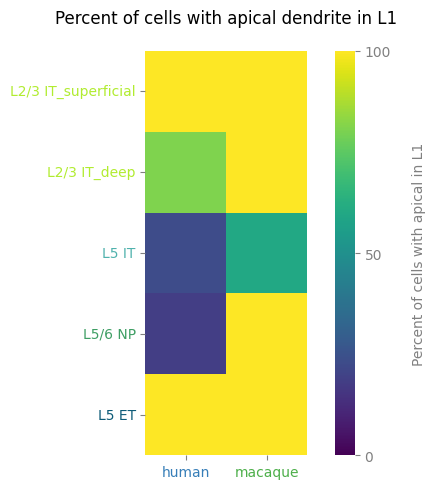

In [69]:
# Plot heatmap
fig_name = os.path.join(OUT_DIR, f'{species_type}_heatmap_apical_L1_reach_by_subclass.pdf')

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(heatmap_df, cmap='viridis', cbar=True, square=True, ax=ax, vmin=0, vmax=100, 
            annot=False, fmt='.0f', annot_kws={'size': 10})

# Format the colorbar
cbar = ax.collections[0].colorbar
cbar.set_label("Percent of cells with apical in L1", rotation=90, labelpad=15, color='grey')
cbar.set_ticks([0, 50, 100])
cbar.ax.yaxis.set_tick_params(color='grey')
for tick in cbar.ax.get_yticklabels():
    tick.set_color('grey')

# Format ticks/labels
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Percent of cells with apical dendrite in L1", pad=20)

# X ticks grey
ax.tick_params(axis='x', colors='grey')
for tick in ax.get_xticklabels():
    tick.set_color('grey')
    
# Y ticks grey
ax.tick_params(axis='y', colors='grey', rotation=0)
for tick in ax.get_yticklabels():
    tick.set_color('grey')
    
# Color X tick labels by species
for tick_label in ax.get_xticklabels():
    text = tick_label.get_text()
    if text in species_colors:
        tick_label.set_color(species_colors[text])
        
# Color Y tick labels by subclass
for tick_label in ax.get_yticklabels():
    text = tick_label.get_text()
    if text in color_dict:
        tick_label.set_color(color_dict[text])

# Add slashes for NaNs (missing combinations)
for (i, j), val in np.ndenumerate(heatmap_df.values):
    if pd.isna(val):
        ax.add_patch(Rectangle(
            (j, i),
            1, 1,
            fill=False,
            hatch='///',
            edgecolor='lightgrey',
            linewidth=0.0
        ))

plt.tight_layout()
plt.savefig(fig_name, format='pdf', bbox_inches='tight')
plt.show()

Because we removed cells with no apical in L1, not all subclasses have data from all species. 

Plot avgs

In [70]:
subclass_apical_l1_avg = data.groupby(['subclass','species'])['apical_l1_sum_um'].mean().reset_index()
subclass_apical_l1_avg = subclass_apical_l1_avg.rename(columns={'apical_l1_sum_um' : 'apical_l1_avg_um'})
subclass_apical_l1_avg

,subclass,species,apical_l1_avg_um
0,L2/3 IT_deep,human,648.614400
1,L2/3 IT_deep,macaque,1310.378182
2,L2/3 IT_superficial,human,1618.211613
3,L2/3 IT_superficial,macaque,2620.045714
4,L4 IT,human,204.586154
5,L5 ET,human,2569.306667
6,L5 ET,macaque,4205.460000
7,L5 IT,human,173.850000
8,L5 IT,macaque,428.070000
9,L5/6 NP,human,102.030000


Plot

In [71]:
subclass_apical_l1_avg = subclass_apical_l1_avg[subclass_apical_l1_avg.subclass.isin(keep_subclasses)]

if species_type == 'primate':
    figsize=(7,5)
else:
    figsize=(4,5)

/tmp/ipykernel_70413/609168980.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(nobs, rotation=0, ha='center', fontsize=12)
2026-08-28 23:23:54,168 fontTools.subset INFO     maxp pruned
2026-08-28 23:23:54,189 fontTools.subset INFO     cmap pruned
2026-08-28 23:23:54,190 fontTools.subset INFO     kern dropped
2026-08-28 23:23:54,190 fontTools.subset INFO     post pruned
2026-08-28 23:23:54,191 fontTools.subset INFO     FFTM dropped
2026-08-28 23:23:54,195 fontTools.subset INFO     GPOS pruned
2026-08-28 23:23:54,201 fontTools.subset INFO     GSUB pruned
2026-08-28 23:23:54,213 fontTools.subset INFO     glyf pruned
2026-08-28 23:23:54,215 fontTools.subset INFO     Added gid0 to subset
2026-08-28 23:23:54,215 fontTools.subset INFO     Added first four glyphs to subset
2026-08-28 23:23:54,216 fontTools.subset INFO     Closing glyph list over 'MATH': 44 glyphs before
2026-08-28 23:23:

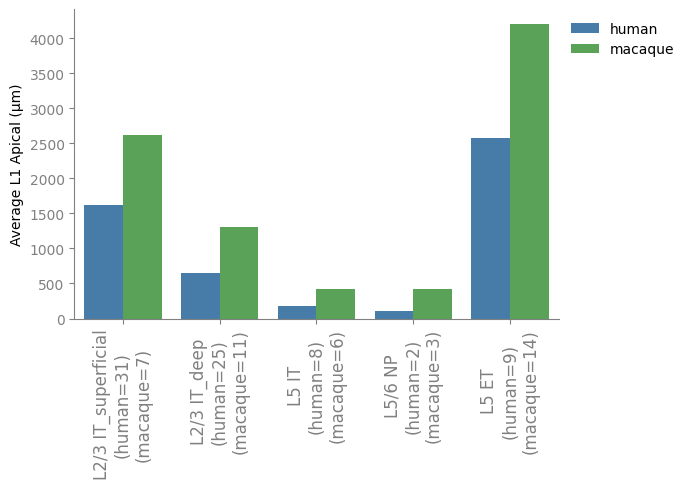

In [72]:
plot_stats = True 

fig_name = os.path.join(OUT_DIR, f"{species_type}_average_l1_apical_length.pdf")
if plot_stats:
    fig_name = fig_name.replace('.pdf', '_withStats.pdf')

fig, ax = plt.subplots(figsize=figsize)
sns.barplot(
    data=subclass_apical_l1_avg,
    x='subclass',
    y='apical_l1_avg_um',
    hue='species',
    hue_order = species_order,
    order = keep_subclasses,
    palette=species_colors,
    ax=ax
)

# --- Add species count labels on x-axis ---
# x_var_order = subclass_order# summary_df['subclass'].unique()

nobs = []

for t in keep_subclasses:
    nh_df = data[(data['subclass'] == t) & (data['species'] == 'human')]
    nq_df = data[(data['subclass'] == t) & (data['species'] == 'macaque')]
    nm_df = data[(data['subclass'] == t) & (data['species'] == 'mouse')]

    nh = len(nh_df)
    nq = len(nq_df)
    nm = len(nm_df)

    if species_type == 'species':
        nobs.append(f"{t}\n(human={nh})\n(macaque={nq})\n(mouse={nm})")
    else:
        nobs.append(f"{t}\n(human={nh})\n(macaque={nq})")

ax.set_xticklabels(nobs, rotation=0, ha='center', fontsize=12)

offsets = np.linspace(-0.25, 0.25, len(subclass_apical_l1_avg.species.unique()))
for i, subclass in enumerate(keep_subclasses):
    for j, sp in enumerate(species_order):
        if len(subclass_apical_l1_avg[(subclass_apical_l1_avg.subclass == subclass) & (subclass_apical_l1_avg.species == sp)]) < 1:
            ax.scatter(
                i + offsets[j],
                80, 
                color=species_colors[sp],
                marker='x',
                s=10,
                linewidths=1,
                zorder=10
            )

if plot_stats:

    # Collect all subclass-level comparisons
    pairs = []
    p_values = []

    # Iterate over each subclass level
    for subclass in keep_subclasses:
        # Skip if no posthoc results OR if the FDR-corrected main test is not significant
        if subclass not in mn_posthoc_pvals:
            continue
        if not mn_pvals_rejected.get(subclass, False):
            continue

        posthoc_results = mn_posthoc_pvals[subclass]

        # Extract species pairs and p-values
        for comp, pval in posthoc_results.items():
            s1, _, s2 = comp.partition('_vs_')
            # Skip NaNs or empty comparisons
            if pd.isna(pval):
                continue
            pairs.append(((subclass, s1), (subclass, s2)))
            p_values.append(pval)

    # Filter to only significant pairs (optional)
    sig_mask = np.array(p_values) < 0.05
    pairs = [p for p, sig in zip(pairs, sig_mask) if sig]
    p_values = [p for p, sig in zip(p_values, sig_mask) if sig]

    if len(pairs) > 0:
        # Temporarily reduce font size for annotations
        original_fontsize = plt.rcParams['font.size']
        plt.rcParams['font.size'] = 10  # smaller stars
        # Create Annotator for grouped boxplot
        annotator = Annotator(
            ax,
            pairs,
            data=subclass_apical_l1_avg,
            x=x_var,
            y='apical_l1_avg_um',
            hue='species',
            order=keep_subclasses,
            hue_order=species_order,
        )
        annotator.configure(test=None, text_format='star', loc='inside')
        annotator.set_pvalues(p_values)
        annotator.annotate()

        # Restore original font size after annotation
        plt.rcParams['font.size'] = original_fontsize

ax.tick_params(axis='both', colors='grey')
ax.xaxis.set_tick_params(labelcolor='grey')
ax.spines['bottom'].set_color('grey')
ax.spines['left'].set_color('grey')

plt.ylabel('Average L1 Apical (µm)')
plt.xlabel('')
plt.xticks(rotation=90)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
sns.despine()
plt.savefig(fig_name, format='pdf', bbox_inches='tight')
plt.show()
